# Data Prep

Builds the shared modeling tables used by both the supervised and unsupervised notebooks. Loads the raw NBA and Kalshi data, checks it, builds home-minus-away features at four checkpoints, assigns a chronological train/test split, and exports one CSV per checkpoint to `data/processed/`.

**Output files:** each file has one row per game and the same 1,141 games, sorted by date. Every feature is a home-minus-away difference, so a positive value means the home team has the edge.

| File | Checkpoint | Columns | Contents |
|---|---|---|---|
| `pregame.csv` | Before tip-off | 24 | Keys and target, rolling stats, Kalshi probability, split |
| `endq1.csv` | End of Q1 | 42 | Everything in `pregame.csv`, plus in-game stats through Q1 |
| `endq2.csv` | End of Q2 | 42 | Everything in `pregame.csv`, plus in-game stats through Q2 |
| `endq3.csv` | End of Q3 | 42 | Everything in `pregame.csv`, plus in-game stats through Q3 |

**Column groups:**

- **Keys and target:** `GAME_ID`, `GAME_DATE`, `HOME_WIN` (1 = home team won)
- **Rolling stats, `ROLL_*` (19):** each team's average over its previous 5 games for 17 box-score stats, plus `PTS` and `PLUS_MINUS`
- **Kalshi:** `KALSHI_PROB_HOME`, the market's normalized home-win probability at that checkpoint
- **In-game stats, `IG_*` (18, end-of-quarter files only):** box-score stats through the end of the quarter, plus `IG_SCORE_DIFF`, the current score margin
- **Split:** `SPLIT`, which is `train` for games before Mar 7, 2026 (854 games) and `test` from then on (287 games)

## 1. Setup

Imports libraries and defines constants used throughout the notebook: the data folders, the four prediction checkpoints, and the rolling-average window for pregame features. Raw CSVs are read from `data/raw/` with the `read_data` helper, and processed files are written to `data/processed/`.

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

from pathlib import Path

pd.set_option("display.max_columns", None)

DATA_DIR = Path("../data")
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"
CHECKPOINTS = ["_pre-game", "EndQ1", "EndQ2", "EndQ3"]
IN_GAME = ["EndQ1", "EndQ2", "EndQ3"]
ROLLING_WINDOW = 5  # default rolling average file to use
ROLL_PREFIX = f"{ROLLING_WINDOW}_game_roll_avg_"

VIZ_DIR = Path("../visualizations")
VIZ_DIR.mkdir(exist_ok=True)

def read_data(file_name):
    """Read a CSV from the data folder."""
    return pd.read_csv(RAW_DIR / f"{file_name}.csv")

## 2. Load Data

Loads the CSVs produced by `01_nba_stats_data.ipynb` and `02_kalshi_data.ipynb`: full-game box scores (used to build leak-free rolling features, never as direct inputs), per-checkpoint game tables with Kalshi tickers and outcomes, in-game box stats at each quarter checkpoint, and Kalshi market snapshots. 

In [2]:
full = read_data("_team-box-stats(full-game)")
main = {checkpoint: read_data(f"main({checkpoint})")                    for checkpoint in CHECKPOINTS}
in_game = {checkpoint: read_data(f"in-game-box-stats({checkpoint})")    for checkpoint in IN_GAME}
kalshi = {checkpoint: read_data(f"kalshi({checkpoint})")                for checkpoint in CHECKPOINTS}
rolling_avg = read_data(f"roll-avg-only({ROLLING_WINDOW}GAME)")

**Row counts and coverage:** Confirms each checkpoint table covers the expected number of games, how many games have a matching Kalshi market for each team, that the in-game and rolling stats have two team rows per game, and the home-team win rate.

In [3]:
for checkpoint in CHECKPOINTS:
    m, k = main[checkpoint], kalshi[checkpoint]
    tickers = set(k["KALSHI_ID"])
    print(
        f"{checkpoint:10s} games={m['GAME_ID'].nunique():5d}  "
        f"kalshi_rows={len(k):5d}  "  
        f"home_mkt_found={m['KALSHI_ID_HOME'].isin(tickers).mean():.1%}  "
        f"away_mkt_found={m['KALSHI_ID_AWAY'].isin(tickers).mean():.1%}"
    )
print()

for checkpoint in IN_GAME:
    print(f"in-game {checkpoint}: {len(in_game[checkpoint])} team rows -> {in_game[checkpoint]['GAME_ID'].nunique()} games")
print()

print(f"rolling ({ROLLING_WINDOW}g): {len(rolling_avg)} team rows -> {rolling_avg['GAME_ID'].nunique()} games")

home_win_rate = (main["_pre-game"]["WINNER"] == main["_pre-game"]["NAME_HOME"]).mean()
print(f"home win rate: {home_win_rate:.1%}")

_pre-game  games= 1225  kalshi_rows= 2444  home_mkt_found=99.8%  away_mkt_found=99.8%
EndQ1      games= 1225  kalshi_rows= 2448  home_mkt_found=99.9%  away_mkt_found=99.9%
EndQ2      games= 1225  kalshi_rows= 2448  home_mkt_found=99.9%  away_mkt_found=99.9%
EndQ3      games= 1225  kalshi_rows= 2444  home_mkt_found=99.8%  away_mkt_found=99.8%

in-game EndQ1: 2460 team rows -> 1230 games
in-game EndQ2: 2460 team rows -> 1230 games
in-game EndQ3: 2460 team rows -> 1230 games

rolling (5g): 2310 team rows -> 1159 games
home win rate: 55.4%


**Games missing from the checkpoint tables:** Explains the 5-game gap above (1,230 games in the box-score tables vs. 1,225 in the checkpoint tables). All five are neutral-site games (Mexico City, Las Vegas NBA Cup semifinals, Berlin, London), where there’s no home or away team, so they’re excluded.

In [4]:
missing = set(full["GAME_ID"]) - set(main["_pre-game"]["GAME_ID"])

full[full["GAME_ID"].isin(missing)][["GAME_ID", "GAME_DATE", "MATCHUP"]].drop_duplicates("GAME_ID")

,GAME_ID,GAME_DATE,MATCHUP
161,22500147,2025-11-01,DAL @ DET
744,22501229,2025-12-13,NYK @ ORL
746,22501230,2025-12-13,SAS @ OKC
1213,22500578,2026-01-15,ORL @ MEM
1258,22500602,2026-01-18,ORL @ MEM


## 3. Exploratory Data Analysis

Before building features, these checks confirm the data behaves as expected:

- **Kalshi prices:** the home and away midpoints sum to about 1, and the market gets more accurate as the game goes on.
- **In-game stats:** the team leading at each checkpoint usually wins, so the box score carries real signal.

The `kalshi_long` table built here is also the source of the `KALSHI_PROB_HOME` feature in Section 4.

**Kalshi implied probabilities:** Builds one row per game and checkpoint with the bid/ask midpoint for each team’s market and the actual outcome. Used by the checks below and by the Kalshi feature.

In [5]:
def kalshi_home_prob(checkpoint):
    """One row per game: Kalshi bid/ask midpoint for each team's market, plus the outcome."""
    m = main[checkpoint][["GAME_ID", "KALSHI_ID_HOME", "KALSHI_ID_AWAY", "NAME_HOME", "WINNER"]].copy()
    k = kalshi[checkpoint].copy()
    k["MID"] = (k["yes_bid_close"] + k["yes_ask_close"]) / 2
    mid = k.set_index("KALSHI_ID")["MID"]

    m["PROB_HOME"] = m["KALSHI_ID_HOME"].map(mid)
    m["PROB_AWAY"] = m["KALSHI_ID_AWAY"].map(mid)
    m["HOME_WIN"] = (m["WINNER"] == m["NAME_HOME"]).astype(int)
    m["CHECKPOINT"] = checkpoint

    return m

kalshi_long = pd.concat([kalshi_home_prob(checkpoint) for checkpoint in CHECKPOINTS], ignore_index=True)

In [6]:
kalshi_long.head()

,GAME_ID,KALSHI_ID_HOME,KALSHI_ID_AWAY,NAME_HOME,WINNER,PROB_HOME,PROB_AWAY,HOME_WIN,CHECKPOINT
0,22500002,KXNBAGAME-25OCT21GSWLAL-LAL,KXNBAGAME-25OCT21GSWLAL-GSW,Los Angeles Lakers,Golden State Warriors,0.445,0.565,0,_pre-game
1,22500001,KXNBAGAME-25OCT21HOUOKC-OKC,KXNBAGAME-25OCT21HOUOKC-HOU,Oklahoma City Thunder,Oklahoma City Thunder,0.685,0.340,1,_pre-game
2,22500086,KXNBAGAME-25OCT22WASMIL-MIL,KXNBAGAME-25OCT22WASMIL-WAS,Milwaukee Bucks,Milwaukee Bucks,0.805,0.195,1,_pre-game
3,22500003,KXNBAGAME-25OCT22CLENYK-NYK,KXNBAGAME-25OCT22CLENYK-CLE,New York Knicks,New York Knicks,0.455,0.545,1,_pre-game
4,22500081,KXNBAGAME-25OCT22MIAORL-ORL,KXNBAGAME-25OCT22MIAORL-MIA,Orlando Magic,Orlando Magic,0.755,0.245,1,_pre-game


**Market consistency:** Each game has two markets (home wins, away wins). If prices are sensible, the two midpoints should sum to roughly 1.

In [7]:
kalshi_long["PROB_SUM"] = kalshi_long["PROB_HOME"] + kalshi_long["PROB_AWAY"]
kalshi_long.groupby("CHECKPOINT", sort=False)["PROB_SUM"].describe()[["count", "mean", "min", "max"]]

,count,mean,min,max
CHECKPOINT,,,,
_pre-game,1222.0,1.003061,0.98,1.04
EndQ1,1224.0,1.001855,0.98,1.03
EndQ2,1224.0,1.001838,0.97,1.04
EndQ3,1222.0,1.000859,0.97,1.03


**Kalshi accuracy by checkpoint:** As a game progresses, the market should become more confident and more accurate: the favorite should win more often and the Brier score should fall.

In [8]:
def market_summary(data):
    data = data.dropna(subset=["PROB_HOME"])
    return pd.Series({
        "games": len(data),
        "favorite_win_rate": ((data["PROB_HOME"] > 0.5) == data["HOME_WIN"]).mean(),
        "avg_confidence": (data["PROB_HOME"] - 0.5).abs().mean() + 0.5,
        "brier": ((data["PROB_HOME"] - data["HOME_WIN"]) ** 2).mean(),
    })

kalshi_long.groupby("CHECKPOINT", sort=False).apply(market_summary, include_groups=False).round(4)

,games,favorite_win_rate,avg_confidence,brier
CHECKPOINT,,,,
_pre-game,1222.0,0.6948,0.6990,0.1939
EndQ1,1224.0,0.7271,0.7276,0.1805
EndQ2,1224.0,0.7712,0.7719,0.1501
EndQ3,1222.0,0.8339,0.8307,0.1132


**In-game leader win rate:** How often the team leading at each checkpoint goes on to win (ties excluded). This shows how much signal the in-game stats carry and gives a benchmark to compare the Kalshi numbers against.

In [9]:
leader = []
for checkpoint in IN_GAME:
    home = in_game[checkpoint][in_game[checkpoint]["MATCHUP"].str.contains("vs.")]
    not_tied = home["PLUS_MINUS"] != 0
    leader_wins = ((home["PLUS_MINUS"] > 0) == (home["WL"] == "W"))[not_tied].mean()
    leader.append(leader_wins)
    print(f"{checkpoint}: leader wins {leader_wins:.1%}  ({not_tied.sum()} non-tied games)")

EndQ1: leader wins 65.6%  (1169 non-tied games)
EndQ2: leader wins 74.4%  (1196 non-tied games)
EndQ3: leader wins 82.5%  (1194 non-tied games)


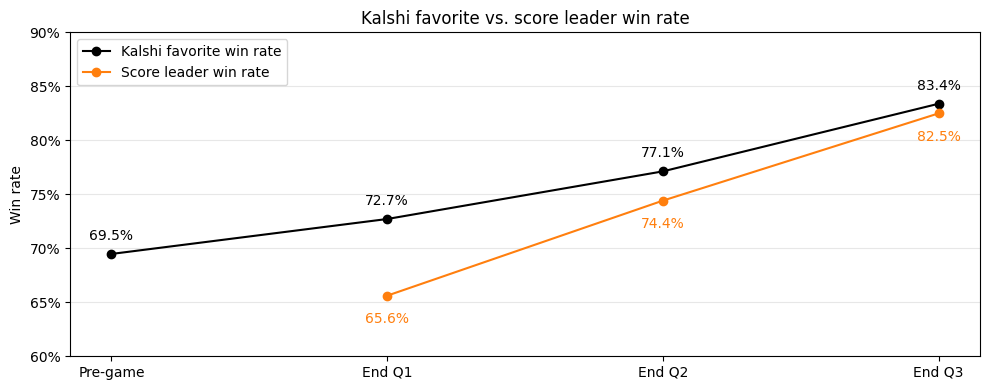

In [10]:
labels = ["Pre-game", "End Q1", "End Q2", "End Q3"]

market = kalshi_long.groupby("CHECKPOINT", sort=False).apply(market_summary, include_groups=False)

plt.figure(figsize=(10,4))

plt.plot(labels, market["favorite_win_rate"], marker="o", color="black", label="Kalshi favorite win rate")
plt.plot(labels[1:], leader, marker="o", color="tab:orange", label="Score leader win rate")

for x, y in zip(labels, market["favorite_win_rate"]):
    plt.annotate(f"{y:.1%}", (x, y), textcoords="offset points", xytext=(0, 10), ha="center")

for x, y in zip(labels[1:], leader):
    plt.annotate(f"{y:.1%}", (x, y), textcoords="offset points", xytext=(0, -20), ha="center", color="tab:orange")

plt.ylim(0.6, 0.9)
plt.ylabel("Win rate")
plt.gca().yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
plt.grid(axis="y", alpha=0.3)
plt.title("Kalshi favorite vs. score leader win rate")
plt.legend()

plt.tight_layout()
plt.savefig(VIZ_DIR / "01_prep_favorite_vs_leader.png", dpi=300, bbox_inches="tight")
plt.show()

**Kalshi favorite vs. score leader, chart:** Compares how often the Kalshi favorite wins with how often the team leading on the scoreboard wins at each checkpoint. Both rise as the game goes on, but the market favorite wins more often at every in-game checkpoint. The gap is largest at End Q1 (72.7% vs. 65.6%) and shrinks to under a point by End Q3, when the score margin carries most of the information. Pre-game has no score leader, so only the Kalshi line starts there. The leader rates exclude tied games, and both lines use the full season rather than the 1,141-game modeling set.

## 4. Feature Engineering

Builds one modeling table per checkpoint, with one row per game and the target `HOME_WIN`. Every feature is a home-minus-away difference, so a positive value means the home team has the edge. Features come from 3 sources:

- **Rolling stats (`ROLL_`)**: each team's average over its previous games, available at every checkpoint
- **In-game stats (`IG_`)**: box score through the end of the quarter, plus the current score margin (End of quarter 1-3 only)
- **Kalshi (`KALSHI_PROB_HOME`)**: the market's implied home win probability at that checkpoint

**Leakage check, rolling stats:** Recomputes one team's rolling averages from the full-game box scores using only the 5 games *before* each matchup, then compares them to the rolling file. FGM checks the simple average, and FG_PCT checks the weighted version (total makes / total attempts over the window). Across 77 games, FGM matches exactly and FG_PCT differs by at most 0.005, so the rolling features contain no information from the game being predicted.

In [11]:
# recompute one team's rolling stats from the raw box scores, using only prior games
team = full["TEAM_ID"].iloc[0]
f = full[full["TEAM_ID"] == team].sort_values("GAME_DATE").set_index("GAME_ID")
prior = f[["FGM", "FGA"]].shift(1).rolling(ROLLING_WINDOW)

expected = pd.DataFrame({
    "FGM": prior.mean()["FGM"],
    "FG_PCT": prior.sum()["FGM"] / prior.sum()["FGA"],
})

from_file = (rolling_avg[rolling_avg["TEAM_ID"] == team].set_index("GAME_ID")[[f"{ROLL_PREFIX}FGM", f"{ROLL_PREFIX}FG_PCT"]])
from_file.columns = ["FGM", "FG_PCT"]

check = expected.join(from_file, lsuffix="_expected", rsuffix="_file", how="inner")
print(f"games compared:  {len(check)}")
print(f"max FGM diff:    {(check['FGM_expected'] - check['FGM_file']).abs().max():.4f}")
print(f"max FG_PCT diff: {(check['FG_PCT_expected'] - check['FG_PCT_file']).abs().max():.4f}")

games compared:  77
max FGM diff:    0.0000
max FG_PCT diff: 0.0050


**Feature builders:** Helper functions that turn each source into game-level features. `home_away_diff` pairs each game's home and away rows and drops games missing either side. The in-game score margin uses the home team's `PLUS_MINUS` directly, since a home-minus-away difference would double it. Kalshi prices are normalized by dividing the home midpoint by the sum of the home and away midpoints, so the two probabilities add up to exactly 1. This removes the small extra amount the market's spread adds to the prices.

In [12]:
STAT_COLS = ["FGM", "FGA", "FG_PCT", "FG3M", "FG3A", "FG3_PCT", "FTM", "FTA", "FT_PCT",
             "OREB", "DREB", "REB", "AST", "STL", "BLK", "TOV", "PF"]

def home_away_diff(df, cols, prefix):
    """Home-minus-away difference for each stat, one row per game (games missing a side are dropped)."""
    is_home = df["MATCHUP"].str.contains("vs.", regex=False)
    home = df[is_home].set_index("GAME_ID")[cols]
    away = df[~is_home].set_index("GAME_ID")[cols]
    home, away = home.align(away, join="inner") # keep only games with both a home and an away row
    return (home - away).add_prefix(prefix) # gets home/away diff by calculating home minus away

def rolling_features():
    """Builds pre-game team strength features based on rolling average values."""
    cols = [ROLL_PREFIX + stat for stat in STAT_COLS + ["PTS", "PLUS_MINUS"]]
    features = home_away_diff(rolling_avg, cols, "ROLL_")
    return features.rename(columns=lambda col: col.replace(ROLL_PREFIX, "")) # cleans up rolling average column names ('ROLL_5_game_roll_avg_FG_PCT' to 'ROLL_FG_PCT')

def in_game_features(checkpoint):
    """Builds features from the box score at the end of chosen quarter (checkpoint)."""
    df = in_game[checkpoint]
    features = home_away_diff(df, STAT_COLS, "IG_")
    home = df[df["MATCHUP"].str.contains("vs.", regex=False)].set_index("GAME_ID")
    features["IG_SCORE_DIFF"] = home["PLUS_MINUS"] # gets plus-minus directly to not double the difference with home and away values
    return features

def kalshi_features(checkpoint):
    """Builds Kalshi features at chosen checkpoint."""
    k = kalshi_long[kalshi_long["CHECKPOINT"] == checkpoint].set_index("GAME_ID")
    return pd.DataFrame({"KALSHI_PROB_HOME": k["PROB_HOME"] / (k["PROB_HOME"] + k["PROB_AWAY"])}) # normalizes probability since spread percentages do not always sum to 1

**Modeling tables:** Joins rolling, Kalshi, and in-game features for each checkpoint, keeping only the game ID, date, and target from the main tables. Final-score columns (`PTS_HOME`, `PTS_AWAY`, `WINNER`) are deliberately excluded. Tables are then restricted to games present at all four checkpoints, so every model is evaluated on an identical set of games.

In [13]:
roll = rolling_features()

def build_table(checkpoint):
    base = main[checkpoint][["GAME_ID", "GAME_DATE", "NAME_HOME", "WINNER"]].copy()
    base["HOME_WIN"] = (base["WINNER"] == base["NAME_HOME"]).astype(int)
    base["GAME_DATE"] = pd.to_datetime(base["GAME_DATE"])

    table = (base.set_index("GAME_ID")[["GAME_DATE", "HOME_WIN"]]
             .join(kalshi_features(checkpoint), how="inner")
             .join(roll, how="inner"))
    
    if checkpoint in IN_GAME:
        table = table.join(in_game_features(checkpoint), how="inner")

    return table.dropna(subset=["KALSHI_PROB_HOME"]).sort_values("GAME_DATE")

tables = {checkpoint: build_table(checkpoint) for checkpoint in CHECKPOINTS}

# make sure the same games are at every checkpoint, so all comparisons run on an identical test set
common = tables["_pre-game"].index
for table in tables.values():
    common = common.intersection(table.index)
    
tables = {c: t[t.index.isin(common)] for c, t in tables.items()}

**Train/test split:** Splits games chronologically at the 75th percentile of game dates (Mar 7, 2026) and stores the result in a `SPLIT` column. A random split would let models learn from games played after the ones they’re tested on, which isn’t possible in real prediction.

In [14]:
# split chronologically, not at random; train on the first 75% of the season, test on the final 25%
SPLIT_DATE = tables["_pre-game"]["GAME_DATE"].quantile(0.75)

for checkpoint, table in tables.items():
    tables[checkpoint] = table.assign(SPLIT=np.where(table["GAME_DATE"] < SPLIT_DATE, "train", "test"))

**Final modeling tables:** Confirms that each checkpoint has the same number of games and features, that there are no missing values to handle, and that the train/test split falls where expected. The home win rate differs noticeably between train (53.2%) and test (61.3%), which the next cell looks into.

In [15]:
print(f"split date: {SPLIT_DATE.date()}\n")

for checkpoint, table in tables.items():
    train, test = table[table["SPLIT"] == "train"], table[table["SPLIT"] == "test"]
    nba_features = table.columns.str.startswith(("ROLL_", "IG_")).sum()
    print(f"{checkpoint:10s} games={len(table)}  train={len(train)}  test={len(test)}  "
          f"nba_features={nba_features}  NaNs={table.isna().sum().sum()}  "
          f"home_win train/test={train['HOME_WIN'].mean():.1%}/{test['HOME_WIN'].mean():.1%}")

split date: 2026-03-07

_pre-game  games=1141  train=854  test=287  nba_features=19  NaNs=0  home_win train/test=53.2%/61.3%
EndQ1      games=1141  train=854  test=287  nba_features=37  NaNs=0  home_win train/test=53.2%/61.3%
EndQ2      games=1141  train=854  test=287  nba_features=37  NaNs=0  home_win train/test=53.2%/61.3%
EndQ3      games=1141  train=854  test=287  nba_features=37  NaNs=0  home_win train/test=53.2%/61.3%


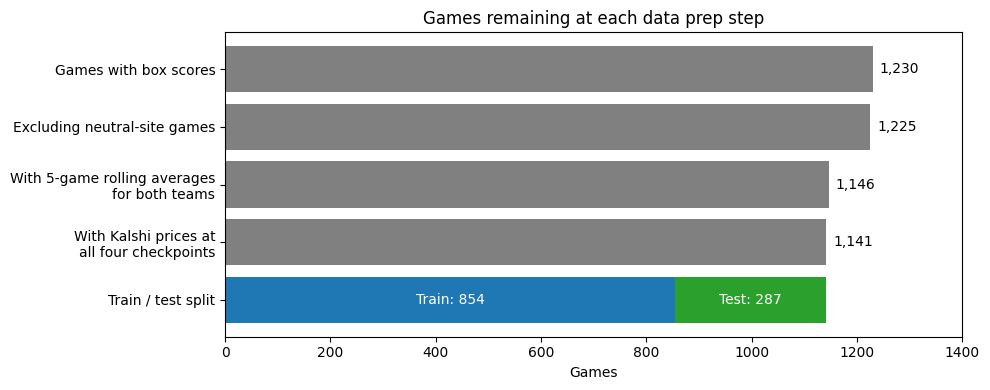

In [16]:
pregame_ids = set(main["_pre-game"]["GAME_ID"])
final = tables["_pre-game"]

steps = {
    "Games with box scores": full["GAME_ID"].nunique(),
    "Excluding neutral-site games": len(pregame_ids),
    "With 5-game rolling averages\nfor both teams": len(pregame_ids & set(roll.index)),
    "With Kalshi prices at\nall four checkpoints": len(final),
}
n_train = (final["SPLIT"] == "train").sum()
n_test = (final["SPLIT"] == "test").sum()

fig, ax = plt.subplots(figsize=(10, 4))

bars = ax.barh(list(steps.keys()), list(steps.values()), color="gray")
ax.bar_label(bars, fmt="{:,.0f}", padding=5)

train_bar = ax.barh("Train / test split", n_train, color="tab:blue")
test_bar = ax.barh("Train / test split", n_test, left=n_train, color="tab:green")
ax.bar_label(train_bar, labels=[f"Train: {n_train}"], label_type="center", color="white")
ax.bar_label(test_bar, labels=[f"Test: {n_test}"], label_type="center", color="white")

ax.invert_yaxis()  # first step at the top
ax.set_xlim(0, 1400)
ax.set_xlabel("Games")
ax.set_title("Games remaining at each data prep step")

plt.tight_layout()
plt.savefig(VIZ_DIR / "02_prep_data_pipeline.png", dpi=300, bbox_inches="tight")
plt.show()

**Data pipeline:** Shows how many games remain after each filtering step. Removing neutral-site games drops 5, and requiring a 5-game rolling average for both teams drops 79 early-season games, the largest cut. Requiring Kalshi prices and in-game stats at all four checkpoints removes 5 more, leaving 1,141 games, which are split chronologically into 854 training and 287 test games.

**Home win rate by month:** Breaks down the home win rate by month to explain the train/test gap. November through January hold steady at 54–56%, close to the season average. February dips to 47% and sits entirely in the training set, pulling its rate down. March and April rise to about 60%, which falls in the test period. That timing lines up with the trade deadline and the late season, when tanking and resting players are common. 

The shift reflects the real season rather than a data error, but it means models are tested on a period with a different base rate than they were trained on. For that reason, every model is compared against baselines computed on the same test games. October has only 2 games because teams need 5 prior games before they have a rolling average.

In [17]:
table = tables["_pre-game"]
table.groupby(table["GAME_DATE"].dt.to_period("M"))["HOME_WIN"].agg(["mean", "count"]).round(3)

,mean,count
GAME_DATE,,
2025-10,0.000,2
2025-11,0.556,216
2025-12,0.538,195
2026-01,0.557,228
2026-02,0.470,166
2026-03,0.601,238
2026-04,0.594,96


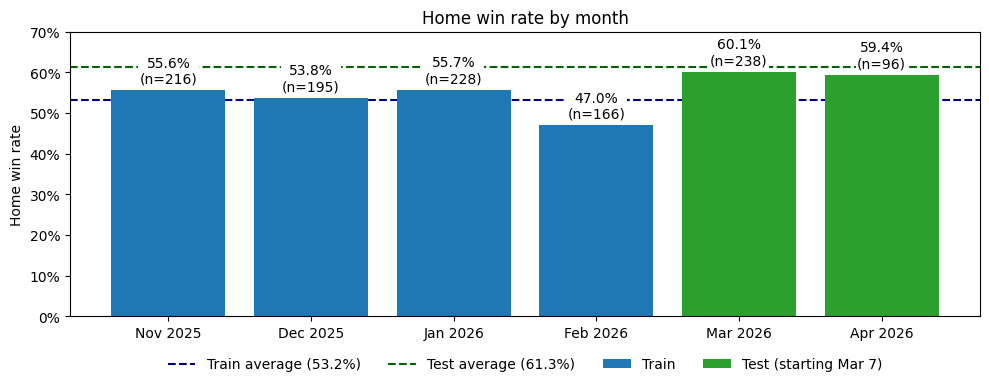

In [18]:
monthly = table.groupby(table["GAME_DATE"].dt.to_period("M"))["HOME_WIN"].agg(["mean", "count"]).round(3)
monthly = monthly[monthly["count"] >= 10]
monthly.index = monthly.index.strftime("%b %Y")
season_avg = table["HOME_WIN"].mean()

is_train = [month in ["Nov 2025", "Dec 2025", "Jan 2026", "Feb 2026"] for month in monthly.index]
train, test = monthly[is_train], monthly[[not t for t in is_train]]

fig, ax = plt.subplots(figsize=(10, 4))

for data, color, label in  [(train, "tab:blue", "Train"), (test, "tab:green", "Test (starting Mar 7)")]:
    bars = ax.bar(data.index, data["mean"], color=color, label=label)
    ax.bar_label(bars, labels=[f"{m:.1%}\n(n={c})" for m, c in zip(data["mean"], data["count"])],
                 padding=3, bbox=dict(facecolor="white", edgecolor="none", pad=1))

for split, color in [("train", "navy"), ("test", "darkgreen")]:
    rate = table.loc[table["SPLIT"] == split, "HOME_WIN"].mean()
    ax.axhline(rate, color=color, linestyle="--", label=f"{split.title()} average ({rate:.1%})", zorder=0)

ax.set_ylim(0, 0.7)
ax.set_ylabel("Home win rate")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.set_title("Home win rate by month")
#ax.legend(loc="upper left")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4, frameon=False)

plt.tight_layout()
plt.savefig(VIZ_DIR / "03_prep_home_win_rate_by_month.png", dpi=300, bbox_inches="tight")
plt.show()

**Home win rate by month, chart:** Visualizes the table above, with training months in blue and test months in green. The dashed lines mark the train (53.2%) and test (61.3%) averages. The test average sits above both test-month bars because the March bar also includes 47 games from March 1–6, which fall in the training period and had a 51.1% home win rate. The March games from the 7th on had a 62.3% home win rate. October is left out because it has only 2 games.

## 5. Export Processed Data

Saves one CSV per checkpoint (`pregame`, `endq1`, `endq2`, `endq3`) to `data/processed/`, each with the same 1,141 games, the `HOME_WIN` target, and a `SPLIT` column marking the chronological train/test split. The supervised and unsupervised notebooks load these files so both analyses run on identical games and features.

In [19]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

FILE_NAMES = {"_pre-game": "pregame", "EndQ1": "endq1", "EndQ2": "endq2", "EndQ3": "endq3"}

for checkpoint, name in FILE_NAMES.items():
    output = tables[checkpoint].reset_index()  # game_id back to a column
    output.to_csv(PROCESSED_DIR / f"{name}.csv", index=False)
    print(f"{name}: {len(output)} rows, {output.shape[1]} columns")

pregame: 1141 rows, 24 columns
endq1: 1141 rows, 42 columns
endq2: 1141 rows, 42 columns
endq3: 1141 rows, 42 columns
